# RM3 · From the DFT you know to the continuous Fourier transform

**Part:** Math refresher · **Reading time:** ~25 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [RM2 Complex numbers](RM2_Complex_Numbers_and_Rotations.ipynb), then [RM4 Fourier properties](RM4_Fourier_Properties.ipynb)

MRI theory is written with the **continuous** Fourier transform (integrals over position $x$ and spatial
frequency $k$), while MRI data are processed with the **DFT/FFT** (sums over array indices). To move
between book and code you need three things: the MRI sign/2π convention, the exact link between the two
(including the scale factor $\Delta x$ and the axis $k_m$), and the `fftshift` bookkeeping. This notebook
builds all three and verifies them numerically against known analytic transforms.

## Learning goals

1. State the continuous FT and its inverse in the MRI convention $e^{-i2\pi kx}$, with units, and convert to the angular-frequency ($\omega$) convention.
2. Show that $\Delta x\cdot\mathrm{FFT}$ approximates samples of the continuous FT, with $\Delta x\,\Delta k=1/N$, $\text{FOV}=1/\Delta k$, $k$-range $=1/\Delta x$.
3. Build the frequency axis correctly and explain what `fftshift`/`ifftshift` do and why `mt.fftc` exists.
4. Reproduce analytic transforms (rect → sinc, Gaussian → Gaussian, FID → Lorentzian) with the FFT, including correct scaling.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x$ | position | m | |
| $k$ | spatial frequency (k-space coordinate) | m⁻¹ = cycles/m | $\lvert k\rvert$ up to ~500 m⁻¹ |
| $f(x)$, $F(k)$ | a function of position and its Fourier transform | [f], [f]·m | here $f$ is a *function*, not a frequency |
| $\mathcal F\{\cdot\}$, $\mathcal F^{-1}\{\cdot\}$ | Fourier transform and inverse | | kernel $e^{-i2\pi kx}$ |
| $t$, $f$ | time and (ordinary) frequency | s, Hz | used for time signals $s(t)\leftrightarrow S(f)$ |
| $\omega=2\pi f$ | angular frequency | rad/s | |
| $s(t)$, $S(f)$ | a time signal (e.g. FID) and its spectrum | a.u., a.u.·s | |
| $N$ | number of samples | – | 64–512 |
| $n,\ m$ | sample index in position (time) and in frequency | – | $0\dots N-1$ |
| $\Delta x$, $\Delta k$ | sample spacing in position and in k | m, m⁻¹ | $\Delta x\,\Delta k=1/N$ |
| $x_n,\ k_m$ | sample positions $(n-N/2)\Delta x$ and $(m-N/2)\Delta k$ | m, m⁻¹ | centred grids |
| $FOV=N\Delta x=1/\Delta k$ | field of view (length covered by the samples) | m | 0.2–0.5 m |
| $k_{max}=1/(2\Delta x)$ | largest k on the grid | m⁻¹ | |
| $\Delta t$, $BW_{read}=1/\Delta t$ | dwell time, receiver bandwidth | s, Hz | 2–20 µs, ±16–±250 kHz |
| $W$, $a$ | width of a rect, width parameter of a Gaussian | m | |
| $\bar\gamma$, $G$ | gyromagnetic ratio, gradient amplitude | Hz/T, T/m | 42.58 MHz/T, 10–40 mT/m |
| $\Delta f$, $T_2^*$ | off-resonance, effective transverse decay time | Hz, s | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. The continuous FT, MRI convention

You know the DFT of $N$ samples:

$$X[m]=\sum_{n=0}^{N-1}x[n]\,e^{-i2\pi mn/N},\qquad m=0,\dots,N-1.$$

In words: correlate the samples with a complex wave that makes $m$ full cycles across the array.

The continuous FT replaces "array of samples" by a function of a continuous variable, and the sum by an integral:

$$F(k)=\mathcal F\{f\}(k)=\int_{-\infty}^{\infty}f(x)\,e^{-i2\pi kx}\,dx,\qquad f(x)=\mathcal F^{-1}\{F\}(x)=\int_{-\infty}^{\infty}F(k)\,e^{+i2\pi kx}\,dk.$$

In words: $F(k)$ measures how much of the complex wave $e^{i2\pi kx}$ — a wave with $k$ **cycles per metre** — is contained in $f$; the inverse rebuilds $f$ by adding up all these waves with weights $F(k)$.
Where: $x$ = position [m], $k$ = spatial frequency [m⁻¹, i.e. cycles/m], $f$ = any (complex) function of position, $F$ its transform.

**Units.** The exponent must be dimensionless, so $k$ has the inverse unit of $x$. Because of the $dx$, $F$ has the units of $f$ times metres.
The same formula with $t$ [s] and $f$ [Hz] is the time–frequency version. In MRI, the k-space coordinate is
$k(t)=\bar\gamma\int_0^tG(\tau)\,d\tau$, with units (Hz/T)·(T/m)·s = 1/m ✓.

### Conventions you will meet (and how to convert)

| name | forward | inverse | used by |
|---|---|---|---|
| ordinary frequency (**MRI, this series**) | $F(k)=\int f(x)e^{-i2\pi kx}dx$ | $f(x)=\int F(k)e^{+i2\pi kx}dk$ | MRI literature (Nishimura, Larson), Bracewell, numpy's DFT sign |
| angular frequency | $F(\omega)=\int f(t)e^{-i\omega t}dt$ | $f(t)=\dfrac{1}{2\pi}\int F(\omega)e^{+i\omega t}d\omega$ | physics, control engineering |
| angular, unitary | $\dfrac{1}{\sqrt{2\pi}}\int f(t)e^{-i\omega t}dt$ | $\dfrac{1}{\sqrt{2\pi}}\int F(\omega)e^{+i\omega t}d\omega$ | some maths texts |

The angular version is the ordinary one evaluated at $f=\omega/2\pi$. The ordinary version needs **no** $2\pi$ prefactors anywhere — one reason MRI uses it.
Every theorem acquires $2\pi$'s in the angular version (e.g. the pair rect $\leftrightarrow$ sinc becomes $\mathrm{rect}(t/T)\leftrightarrow T\,\mathrm{sinc}(\omega T/2\pi)$), so check the convention before copying formulas from a table.

> **⚠️ Common confusion:** the DFT index $m$ is "cycles across the whole array", not cycles per metre. You get physical units
> only after dividing by the array length: $k_m=m/(N\Delta x)$. The rest of this notebook makes that precise.

## 2. The DFT approximates samples of the continuous FT

Sample $f$ on a centred grid $x_n=(n-N/2)\Delta x$ and approximate the integral by a Riemann sum, evaluated on a centred
frequency grid $k_m=(m-N/2)\Delta k$:

$$F(k_m)\approx\Delta x\sum_{n=0}^{N-1}f(x_n)\,e^{-i2\pi k_mx_n}.$$

In words: area of thin strips of width $\Delta x$. Where: $\Delta x$ = sample spacing [m], $\Delta k$ = frequency spacing [m⁻¹].

The sum is a DFT exactly when $k_mx_n=(m-N/2)(n-N/2)/N$, i.e. when

$$\boxed{\;\Delta x\,\Delta k=\frac1N\;}\quad\Longleftrightarrow\quad \Delta k=\frac{1}{N\Delta x}=\frac{1}{FOV},\qquad \text{k-range}=N\Delta k=\frac{1}{\Delta x}.$$

In words: the frequency spacing is one over the length you sampled, and the frequency range is one over the sample spacing.
Read backwards, this is MRI's most important design rule: the k-space spacing $\Delta k$ sets the **field of view** $FOV=1/\Delta k$,
and the k-space extent $\pm k_{max}$ sets the **pixel size** $\Delta x=1/(2k_{max})$ ([G1 FOV and resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)).

The index shifts by $N/2$ are what `fftshift`/`ifftshift` take care of:

$$F(k_m)\;\approx\;\Delta x\cdot\texttt{fftshift(fft(ifftshift(f)))}[m]\;=\;\Delta x\sqrt N\cdot\texttt{mt.fftc(f)}[m].$$

In words: `ifftshift` moves the sample at $x=0$ (index $N/2$) to index 0, where `fft` expects it; `fft` puts $k=0$ at index 0 and negative frequencies in the second half;
`fftshift` moves $k=0$ back to the middle. `mt.fftc` does exactly this, with `norm="ortho"` (a factor $1/\sqrt N$, which makes the transform unitary and is convenient for noise — see [RM4](RM4_Fourier_Properties.ipynb)).

Let's check this with a brute-force sum:

In [2]:
N, dx = 64, 2e-3                              # 64 samples, 2 mm spacing -> FOV = 12.8 cm
x = (np.arange(N) - N // 2) * dx              # centred position grid [m]
dk = 1 / (N * dx)                             # frequency spacing [1/m]
k = (np.arange(N) - N // 2) * dk              # centred frequency grid [1/m]
f = np.exp(-np.pi * (x / 0.02) ** 2) * (1 + 0.5 * np.sin(2 * np.pi * x / 0.03))   # some smooth object

F_direct = dx * np.exp(-1j * 2 * np.pi * np.outer(k, x)) @ f          # Riemann sum, element by element
F_fft = dx * np.fft.fftshift(np.fft.fft(np.fft.ifftshift(f)))
F_fftc = dx * np.sqrt(N) * mt.fftc(f)
print(f"FOV = N dx = {N*dx*100:.1f} cm,  dk = {dk:.3f} 1/m,  k range = {N*dk:.0f} 1/m = 1/dx")
print("max |direct - fft|  =", np.max(np.abs(F_direct - F_fft)))
print("max |direct - fftc| =", np.max(np.abs(F_direct - F_fftc)))
print("frequency axis from np.fft.fftfreq equals k:", np.allclose(np.fft.fftshift(np.fft.fftfreq(N, d=dx)), k))

FOV = N dx = 12.8 cm,  dk = 7.812 1/m,  k range = 500 1/m = 1/dx
max |direct - fft|  = 5.03400841149828e-18
max |direct - fftc| = 5.03400841149828e-18
frequency axis from np.fft.fftfreq equals k: True


The brute-force Riemann sum and the shifted FFT agree to rounding error, and `np.fft.fftfreq(N, d=dx)` (after `fftshift`) gives exactly our $k_m$ axis.

### What goes wrong without the shifts

Forgetting `ifftshift` tells the FFT that the object starts at $x=0$, i.e. it is shifted by half the FOV. By the shift theorem
([RM4](RM4_Fourier_Properties.ipynb)) that multiplies the spectrum by $e^{-i\pi m}=(-1)^m$: the **magnitude is unchanged, but the sign alternates** from sample to sample.
Forgetting `fftshift` leaves $k=0$ at index 0 (the "corners" of a 2D k-space).

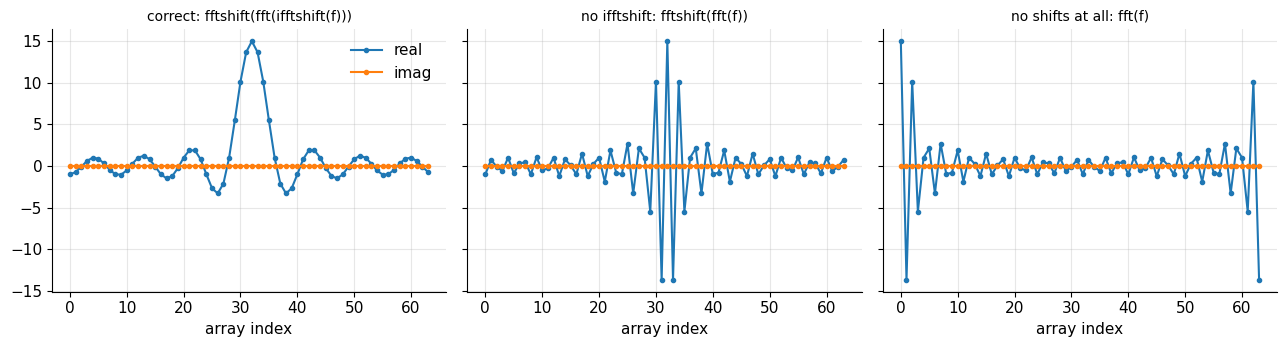

In [3]:
W = 0.03                                       # rect width [m]
f = mt.rect(x / W)
variants = {
    "correct: fftshift(fft(ifftshift(f)))": np.fft.fftshift(np.fft.fft(np.fft.ifftshift(f))),
    "no ifftshift: fftshift(fft(f))":       np.fft.fftshift(np.fft.fft(f)),
    "no shifts at all: fft(f)":             np.fft.fft(f),
}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a_, (name, F) in zip(ax, variants.items()):
    a_.plot(F.real, ".-", label="real"); a_.plot(F.imag, ".-", label="imag")
    a_.set_title(name, fontsize=10); a_.set_xlabel("array index")
ax[0].legend(); plt.tight_layout(); plt.show()

Only the first is a clean, real, centred sinc; the second has the right magnitude but alternating sign, the third has its peak at the array edges.

> **📐 Math note — even vs odd $N$:** with `mt.fftc` the zero position and zero frequency are always at index `N//2`, for even and odd $N$
> (that is why it uses `ifftshift` before and `fftshift` after — for odd $N$ the two are not the same). Use `N//2` consistently when you build axes.

## 3. Check against analytic transforms

Two pairs from [RM5](RM5_Fourier_Pairs_and_Sampling.ipynb), in the MRI convention:

$$\mathrm{rect}\!\left(\frac{x}{W}\right)\;\longleftrightarrow\;W\,\mathrm{sinc}(Wk),\qquad e^{-\pi x^2/a^2}\;\longleftrightarrow\;a\,e^{-\pi a^2k^2}.$$

In words: a box of width $W$ [m] transforms into a sinc whose zeros are at $k=\pm1/W,\pm2/W,\dots$ and whose height $W$ equals the box's area;
a Gaussian of width $a$ [m] transforms into a Gaussian of width $1/a$ [m⁻¹]. Where: $\mathrm{sinc}(u)=\sin(\pi u)/(\pi u)$ (`np.sinc`, `mt.sinc`).

We sample a 25.6 cm FOV with 1 mm pixels, as for a head image.

rect(x/W), W = 5 cm   : max |numerical - analytic| = 5.93e-01 mm  (peak 50 mm),  max |imag| = 0.0e+00
Gaussian, a = 2 cm    : max |numerical - analytic| = 3.47e-15 mm  (peak 20 mm),  max |imag| = 0.0e+00


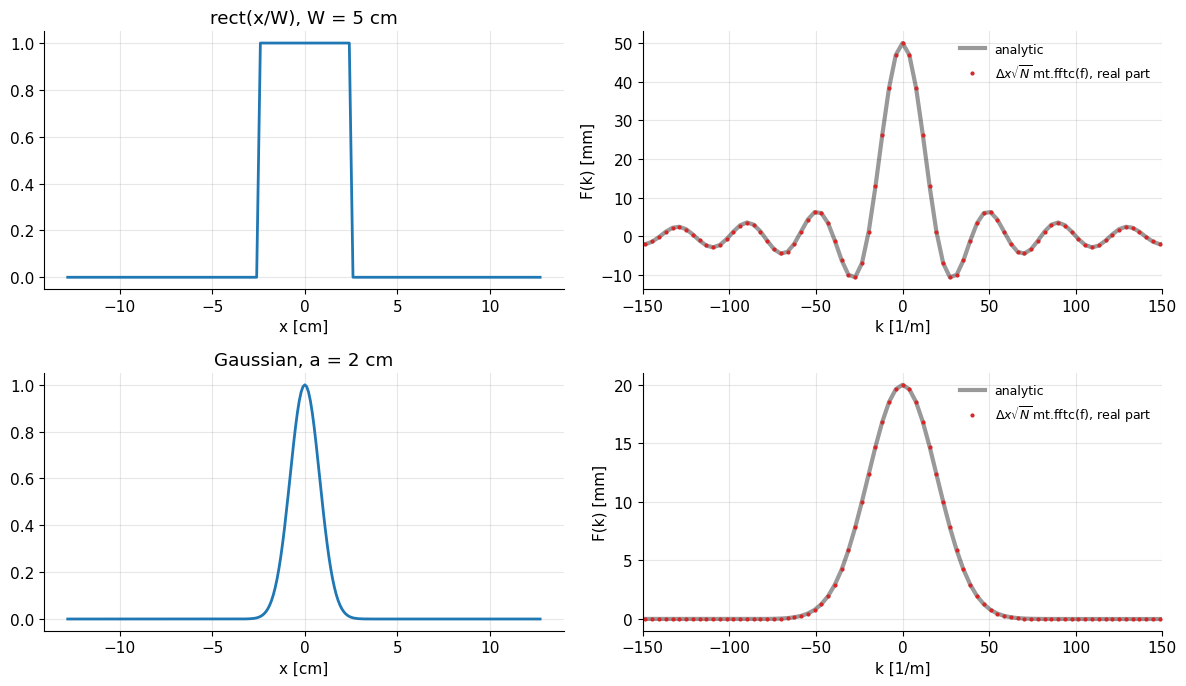

In [4]:
N, dx = 256, 1e-3                             # 1 mm pixels, FOV = 25.6 cm
x = (np.arange(N) - N // 2) * dx              # [m]
k = (np.arange(N) - N // 2) / (N * dx)        # [1/m], spacing 1/FOV
W, a = 0.05, 0.02                             # rect width 5 cm, Gaussian width 2 cm

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for row, (f, F_true, name) in enumerate([
        (mt.rect(x / W), W * np.sinc(W * k), "rect(x/W), W = 5 cm"),
        (np.exp(-np.pi * (x / a) ** 2), a * np.exp(-np.pi * (a * k) ** 2), "Gaussian, a = 2 cm")]):
    F_num = dx * np.sqrt(N) * mt.fftc(f)       # numerical continuous FT
    ax[row, 0].plot(x * 100, f, lw=2); ax[row, 0].set_xlabel("x [cm]"); ax[row, 0].set_title(name)
    ax[row, 1].plot(k, F_true * 1e3, "k-", lw=3, alpha=0.4, label="analytic")
    ax[row, 1].plot(k, F_num.real * 1e3, "C3.", ms=4, label=r"$\Delta x\sqrt{N}\,$mt.fftc(f), real part")
    ax[row, 1].set_xlim(-150, 150); ax[row, 1].set_xlabel("k [1/m]"); ax[row, 1].set_ylabel("F(k) [mm]")
    ax[row, 1].legend(fontsize=9)
    print(f"{name:22s}: max |numerical - analytic| = {np.max(np.abs(F_num - F_true))*1e3:.2e} mm"
          f"  (peak {F_true.max()*1e3:.0f} mm),  max |imag| = {np.max(np.abs(F_num.imag)):.1e}")
plt.tight_layout(); plt.show()

The FFT reproduces both analytic transforms on the correct $k$ axis and with the correct height (the area: 50 mm and 20 mm). The Gaussian agrees to machine precision;
the rect shows a small error because a sharp edge cannot be represented exactly by 1-mm samples and its slowly decaying sinc tails leak past $\pm k_{max}=\pm500$ m⁻¹ (aliasing, [RM5](RM5_Fourier_Pairs_and_Sampling.ipynb)).

> **🧭 Intuition:** the narrow Gaussian (2 cm) has a wide spectrum and the wide rect (5 cm) a narrow sinc: **wide in one domain = narrow in the other**
> ([scaling theorem, RM4](RM4_Fourier_Properties.ipynb)).

## 4. Time signals: the spectrum of an FID

The same machinery works in time. The receiver samples the (demodulated) signal every **dwell time** $\Delta t$, so
the spectrum covers $BW_{read}=1/\Delta t$ and has resolution $1/(N\Delta t)=1/T_{read}$.

Consider an FID from spins at off-resonance $\Delta f$ that decays with $T_2^*$. With MRI's clockwise precession ([RM2](RM2_Complex_Numbers_and_Rotations.ipynb)),
in the rotating frame

$$s(t)=e^{-i2\pi\Delta f\,t}\,e^{-t/T_2^*}\ (t\ge0),\qquad S(f)=\int_0^\infty s(t)e^{-i2\pi ft}dt=\frac{1}{1/T_2^*+i2\pi(f+\Delta f)}.$$

In words: the spectrum is a **Lorentzian** line centred at $f=-\Delta f$ with full width at half maximum $1/(\pi T_2^*)$: faster decay, broader line.
Where: $\Delta f$ = off-resonance [Hz], $T_2^*$ = effective decay time [s], $f$ = frequency [Hz].

Two practical points:
- This signal **starts** at $t=0$ (index 0), so here we do *not* `ifftshift` the input — only `fftshift` the output. Use the centred `mt.fftc` only for data whose origin is in the middle (images, k-space, echoes).
- Because precession is clockwise, a spin at $+\Delta f$ appears at $-\Delta f$ in this FT. Spectroscopy software usually flips the axis; always check which sign convention a plot uses.

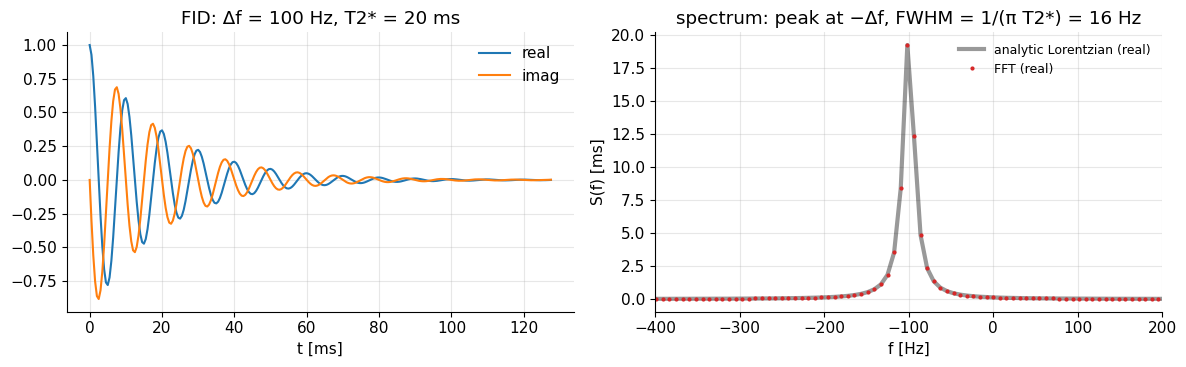

BW = 1/dt = 2000 Hz, frequency resolution 1/(N dt) = 7.8 Hz


In [5]:
dt = 0.5e-3                     # dwell time [s] -> BW = 2 kHz  (slow, spectroscopy-like, to resolve the line)
N = 256
t = np.arange(N) * dt           # starts at 0 [s]
df0, T2s = 100.0, 20e-3         # off-resonance [Hz], T2* [s]
s = np.exp(-1j * 2 * np.pi * df0 * t) * np.exp(-t / T2s)

S_num = dt * np.fft.fftshift(np.fft.fft(s))          # t=0 already at index 0: no ifftshift
S_num -= dt * s[0] / 2                               # trapezoid correction for the jump at t = 0 (optional nicety)
f_ax = np.fft.fftshift(np.fft.fftfreq(N, d=dt))      # [Hz]
S_true = 1 / (1 / T2s + 1j * 2 * np.pi * (f_ax + df0))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(t * 1e3, s.real, label="real"); ax[0].plot(t * 1e3, s.imag, label="imag")
ax[0].set_xlabel("t [ms]"); ax[0].set_title(f"FID: Δf = {df0:g} Hz, T2* = {T2s*1e3:g} ms"); ax[0].legend()
ax[1].plot(f_ax, S_true.real * 1e3, "k-", lw=3, alpha=0.4, label="analytic Lorentzian (real)")
ax[1].plot(f_ax, S_num.real * 1e3, "C3.", ms=4, label="FFT (real)")
ax[1].set_xlim(-400, 200); ax[1].set_xlabel("f [Hz]"); ax[1].set_ylabel("S(f) [ms]")
ax[1].set_title(f"spectrum: peak at −Δf, FWHM = 1/(π T2*) = {1/(np.pi*T2s):.0f} Hz"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
print(f"BW = 1/dt = {1/dt:.0f} Hz, frequency resolution 1/(N dt) = {1/(N*dt):.1f} Hz")

The FFT points lie on the analytic Lorentzian, centred at $-100$ Hz with a width of ≈ 16 Hz — the line width directly measures $T_2^*$.

> **🔧 Engineering reality:** real readouts use dwell times of 2–20 µs ($BW_{read}$ = 50–500 kHz) and $N$ = 128–512 samples, and the scanner's
> digital receiver performs the demodulation, filtering and decimation before you ever see $s(t)$ ([B5 RF system](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb)).

## 5. The DFT is periodic — keep this in mind

The DFT only knows $N$ samples, and its formulas are periodic: $X[m+N]=X[m]$ and the implied signal repeats every $N$ samples.
In continuous terms: **sampling in one domain makes the other domain periodic**. Sampling k-space with spacing $\Delta k$ means the reconstructed
image repeats every $1/\Delta k=FOV$ — anything outside the FOV wraps around (aliasing). This is worked out in [RM5](RM5_Fourier_Pairs_and_Sampling.ipynb).

## Where this shows up in MRI

| Idea | Where it is used |
|---|---|
| MRI signal equation is a continuous FT, $s(t)=\int m(x)e^{-i2\pi k(t)x}dx$ | [C2 MRI signal equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb), [F1 Spatial encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |
| $k=\bar\gamma\int G\,dt$ in cycles/m; k-space sampled on a grid | [F2 K-space](../pass2_deep_dive/F2_K-space.ipynb) |
| $FOV=1/\Delta k$, $\Delta x=1/(2k_{max})$ | [G1 FOV and resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) |
| reconstruction = (centred) inverse FFT, scaling | [F3 Image reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) |
| RF pulse ↔ slice profile is (approximately) a Fourier pair | [E1 RF pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb), [E2 Slice selection](../pass2_deep_dive/E2_Slice_Selection.ipynb) |
| dwell time, readout bandwidth, spectra | [B5 RF system and receive chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb), [D2 In vivo contrast](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |

Compact formula sheet: [MRI math concepts](../reference/MRI_Math_Concepts.ipynb).

## Key takeaways

- MRI convention: $F(k)=\int f(x)e^{-i2\pi kx}dx$, inverse with $e^{+i2\pi kx}$, no $2\pi$ prefactors; $k$ in cycles/m. The $\omega$ convention puts $1/2\pi$ in the inverse.
- $F(k_m)\approx\Delta x\,\texttt{fftshift(fft(ifftshift(f)))}=\Delta x\sqrt N\,\texttt{mt.fftc}(f)$ on $k_m=(m-N/2)\Delta k$.
- $\Delta x\,\Delta k=1/N$: $FOV=1/\Delta k$ and k-range $=1/\Delta x$ — the basis of MRI's FOV/resolution rules.
- `ifftshift` before (origin to index 0), `fftshift` after (zero frequency to the middle). Without them: alternating signs or misplaced centre.
- For signals that start at $t=0$ (FIDs) skip the input `ifftshift`. Clockwise precession puts $+\Delta f$ at $-\Delta f$ in the spectrum.
- Sampling makes the other domain periodic (→ aliasing, RM5).

## Check your understanding

1. You sample 256 points with $\Delta x=0.8$ mm. What are the FOV, $\Delta k$ and the largest $|k|$ on the grid?
<details><summary>Answer</summary>

$FOV=256\times0.8$ mm $=20.48$ cm; $\Delta k=1/FOV\approx4.88$ m⁻¹; $k$ runs from $-1/(2\Delta x)=-625$ m⁻¹ to $+625-4.88$ m⁻¹.

</details>

2. A table lists $\mathcal F\{e^{-a|t|}\}=2a/(a^2+\omega^2)$. What is it in the MRI (ordinary-frequency) convention?
<details><summary>Answer</summary>

Substitute $\omega=2\pi f$: $2a/(a^2+4\pi^2f^2)$. (The forward transforms only differ by the variable; the $1/2\pi$ appears in the angular *inverse*.)

</details>

3. Your FFT of a symmetric, real object comes out with alternating signs. What did you forget?
<details><summary>Answer</summary>

The `ifftshift` before the FFT: the FFT assumed the object's centre at index 0, i.e. shifted by half the FOV, which multiplies the spectrum by $(-1)^m$.

</details>

4. Why must the numerical FT be multiplied by $\Delta x$ (and by $\sqrt N$ when using `mt.fftc`)?
<details><summary>Answer</summary>

$\Delta x$ is the width of each strip in the Riemann sum approximating $\int\dots dx$. `np.fft.fft` does not include it. `mt.fftc` uses `norm="ortho"`, which divides by $\sqrt N$, so that factor has to be undone to match the continuous FT.

</details>

5. A readout uses $\Delta t=4$ µs and 256 samples. What are the receiver bandwidth and the frequency resolution?
<details><summary>Answer</summary>

$BW_{read}=1/\Delta t=250$ kHz (i.e. ±125 kHz); resolution $1/(N\Delta t)=1/(1.024\text{ ms})\approx977$ Hz per sample (= per pixel in a frequency-encoded image).

</details>

---
*New refresher written for this adaptation of P. Larson, "Principles of MRI" (MIT License); see references below.*
*References: R. N. Bracewell, *The Fourier Transform and Its Applications* (McGraw-Hill);
A. V. Oppenheim, A. S. Willsky, *Signals and Systems* (Prentice Hall);
D. G. Nishimura, *Principles of Magnetic Resonance Imaging*;
J. L. Prince, J. M. Links, *Medical Imaging Signals and Systems* (Pearson).*